# Mida el plan aprendido en distintas formas de yacimiento

**Pregunta:** ¿Cómo se compara el valor del plan aprendido con ExTS exacto en distintos arquetipos sintéticos y cuándo debe advertir la regla?

**Nivel:** 2 · Método en práctica

**Prerrequisitos:** Complete el nivel 1 de surrogate aprendido.

**Tiempo de lectura:** 26 minutos

## Objetivos

El dossier del producto evalúa el método en semillas de yacimiento, escenarios y tamaños de grilla disjuntos porque los bloques de un mismo yacimiento comparten características. Este notebook construye cuatro arquetipos sintéticos pequeños, carga un bundle fijo y mide cada plan aprendido contra su plan Expected exacto en el mismo caso. La razón es una medición por caso, no un pronóstico para un yacimiento real desconocido. También ejecutará la regla de advertencia y comparará su recall limpio de una tercera partición con el recall más atractivo, pero sesgado, de la partición usada para elegirla. La lección muestra cómo evaluar un surrogate honestamente: separar particiones por yacimiento, mostrar fallas y nunca sustituir la cota por una predicción. Los gemelos pequeños muestran el flujo pero no reproducen la población validada de 1.008 y 6.912 bloques.

## Preparación

Instale el entorno fijado desde la raíz con `pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2`. Este notebook usa `oreblocks==0.6.5`. Los modelos están comprometidos; este notebook no entrena ni instala nada.

```bash
pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Cargue la canalizacion y el conjunto de modelos comprometidos.
import importlib.metadata as metadata
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
from pipeline.model.learned import LearnedBundle
import oreblocks as ob
print('oreblocks', metadata.version('oreblocks'))

oreblocks 0.6.5


## Datos

Las entradas se generan con la canalización MIT de PhaseFlow. El bundle comprometido contiene `models/expected-time.json`, `models/bound.json` y `models/guard-validation.json`; son artefactos del estudio sintético del producto, no observaciones de una mina nombrada. OreBlocks 0.6.5 aporta el plan TopoSort y la referencia exacta de tiempos esperados. El modelo separó yacimientos por semilla: doce semillas de entrenamiento, seis de validación y una tercera partición disjunta para la regla. Este notebook crea casos con semillas declaradas nuevas. No interprete sus puntuaciones como sustituto del informe persistido ni como evidencia sobre un modelo real.

## Método



In [2]:
# Construya con PhaseFlow un caso didáctico core-halo con semilla.
case = Case(
    id='learned-core-halo-8x8x4', category='teaching',
    title_en='Core halo surrogate lesson', title_es='Leccion surrogate core halo',
    deposit=DepositSpec(kind='twin', archetype='core_halo', dims=(8, 8, 4), seed=223),
    scenario=Scenario(periods=6, discount_rate=0.10,
        capacity_fraction=(0.85, 0.55), resource_names=('mining', 'processing')),
)
instance = build_instance(case)
print('contrato:', instance.report.ok, '| bloques:', instance.n_blocks)

contrato: True | bloques: 256


In [3]:
# Cargue los modelos del repositorio e inspeccione el estudio persistido.
bundle = LearnedBundle.load(Path('../../../models'))
report = bundle.report()
print('Spearman de tiempos esperados retenidos:', report['expectedTime'].get('holdout_spearman'))
print('recall limpio de la regla:', report['guard'].get('validation_recall'))
print('fallas de la regla:', report['guard'].get('validation_failures'), '/', report['guard'].get('validation_n'))

Spearman de tiempos esperados retenidos: 0.8137238468016208
recall limpio de la regla: 0.42857142857142855
fallas de la regla: 133 / 432


Cree cuatro casos con dimensiones y escenario compartidos, variando solo arquetipo y semilla. El diseño pareado permite interpretar la razón por caso.

In [4]:
# Declare casos didácticos cruzados; solo varían arquetipo y semilla.
archetypes = ('porphyry', 'vein', 'layered', 'core_halo')
cases = []
for seed, kind in enumerate(archetypes, start=223):
    cases.append(Case(
        id=f'learned-{kind}', category='teaching', title_en=kind, title_es=kind,
        deposit=DepositSpec(kind='twin', archetype=kind, dims=(8, 8, 4), seed=seed),
        scenario=Scenario(
            periods=6, discount_rate=0.10, capacity_fraction=(0.85, 0.55),
            resource_names=('mining', 'processing'),
        ),
    ))
instances = [build_instance(case) for case in cases]
print([(case.deposit.archetype, inst.n_blocks) for case, inst in zip(cases, instances)])

[('porphyry', 256), ('vein', 256), ('layered', 256), ('core_halo', 256)]


Ejecute el surrogate de cota en los mismos casos generados. Conserve sus valores como predicciones y compárelos con cotas exactas en un estudio de validación separado.

In [5]:
# Prediga una razón de cota por caso sin tratarla como certificado.
bound_ratios = [bundle.predict_bound_ratio(inst, case.scenario) for inst, case in zip(instances, cases)]
print('razones de cota previstas:', np.round(bound_ratios, 3))

razones de cota previstas: [0.473 0.456 0.491 0.349]


Ejecute la ruta aprendida en cada caso y conserve un resultado por yacimiento. Sigue siendo un barrido didáctico, no el estudio disjunto del modelo.

In [6]:
# Infiera un plan aprendido para cada yacimiento generado.
learned = [bundle.for_instance(instance)[0][1] for instance in instances]
print([(instance.archetype, round(result.npv, 2)) for instance, result in zip(instances, learned)])

[('porphyry', 5323568.51), ('vein', 5728468.65), ('layered', 28823212.98), ('core_halo', 1311772.1)]


Calcule ExTS exacto en las mismas instancias y obtenga razones antes de resumir. Una razón cercana a uno es una coincidencia medida en ese yacimiento; no informa sobre yacimientos fuera del conjunto.

In [7]:
# Ejecute planes exactos y calcule razones pareadas por yacimiento.
exact = [ob.solve_cpit(inst.cpit, inst.precedence, method='expected', local_search=False)[0] for inst in instances]
ratios = np.array([learned[i].npv / exact[i].npv for i in range(len(instances))])
print('razones:', np.round(ratios, 3))
print('media:', round(float(ratios.mean()), 3), '| mínimo:', round(float(ratios.min()), 3))

razones: [0.963 0.865 0.914 0.947]
media: 0.922 | mínimo: 0.865


Lea el informe de la regla junto a las razones medidas. El recall limpio de validación es 0,472, así que más de la mitad de las fallas escapan. Un yacimiento real no tiene la etiqueta sintética; allí la respuesta correcta es abstenerse.

In [8]:
# Aplique la regla dependiente de etiqueta solo donde exista ese dato sintético.
flags = [bundle.unreliable_here(inst.cpit, inst.archetype) for inst in instances]
print(list(zip(archetypes, [flag is not None for flag in flags])))
print('recall de validación limpia:', report['guard']['validation_recall'])

[('porphyry', False), ('vein', False), ('layered', False), ('core_halo', False)]
recall de validación limpia: 0.42857142857142855


Grafique las razones pareadas y marque igualdad. El segundo panel conserva recall persistido de la partición de selección y la partición limpia.

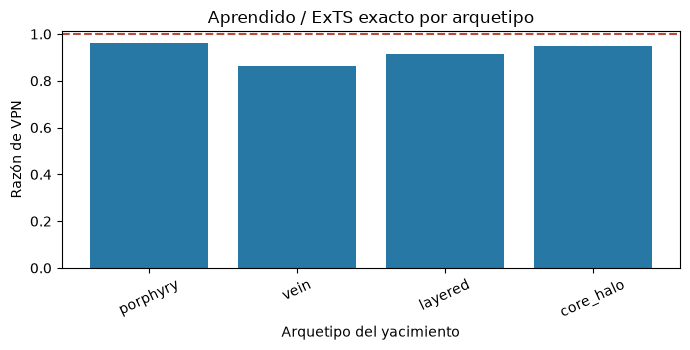

In [9]:
# Grafique razones pareadas aprendido/ExTS y marque igualdad.
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(archetypes, ratios, color='#2878a5')
ax.axhline(1.0, color='#b64b3b', linestyle='--')
ax.set(
    title='Aprendido / ExTS exacto por arquetipo',
    xlabel='Arquetipo del yacimiento', ylabel='Razón de VPN',
)
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
plt.show()

### Figura 1

Las barras comparan la razón VPN aprendido/ExTS por arquetipo generado. Un valor de 1,0 indica igual valor de plan en ese caso; bajo 1,0, el plan aprendido pierde valor frente a ExTS exacto. Los cuatro puntos forman un barrido didáctico determinista, no una muestra estadística. Una razón cercana a uno no demuestra generalización ni cambia la procedencia de la cota.

Ahora inspeccione por separado el recall de la regla en validación y en la partición limpia. Las barras usan valores persistidos, no los cuatro casos didácticos.

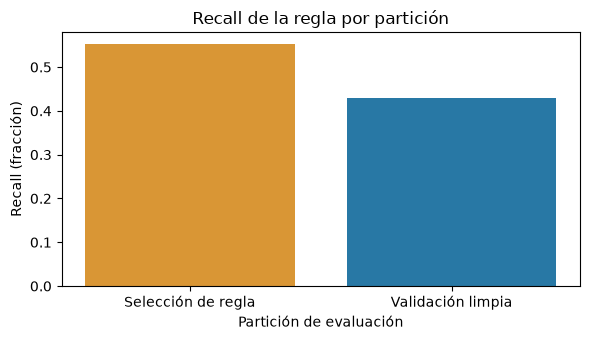

In [10]:
# Compare recall de selección con el de la partición limpia.
fig, ax = plt.subplots(figsize=(6, 3.5))
recalls = [report['expectedTime'].get('failure_rule_recall', 0), report['guard']['validation_recall']]
ax.bar(['Selección de regla', 'Validación limpia'], recalls, color=['#d99635', '#2878a5'])
ax.set(
    title='Recall de la regla por partición',
    xlabel='Partición de evaluación', ylabel='Recall (fracción)',
)
fig.tight_layout()
plt.show()

### Figura 2

La primera barra muestra recall en la partición que informó la selección de la regla; la segunda corresponde a la partición limpia disjunta. El resultado limpio es menor que la mitad, por lo que la regla omite más de la mitad de las fallas medidas. Es una advertencia, no un certificado. En un yacimiento real sin etiqueta sintética de arquetipo, la regla debe abstenerse. La ruta exacta mide el plan al terminar. Los falsos negativos de la regla aparecen en el estudio: la regla por arquetipo captura menos de la mitad de las fallas en ambas particiones medidas. Usa una etiqueta disponible en gemelos generados, pero ausente en un yacimiento real sin clasificar. Por tanto, este panel documenta los límites de la regla y no justifica confiar en casos que deja sin marcar. Espere siempre una comparación directa con el plan exacto cuando la ruta productiva la entregue.

La unidad de validación es un arquetipo generado, no un bloque individual. Dividir bloques al azar desde un mismo depósito sintético filtraría su estructura espacial hacia los conjuntos de entrenamiento y prueba, y exageraría la generalización. Los arquetipos retenidos hacen una pregunta más acotada y útil: ¿conserva valor un modelo entrenado con ciertas geometrías cuando cambia la geometría del depósito? Cuatro arquetipos siguen siendo una muestra pequeña de diversidad geológica; las razones describen estos casos y no estiman una tasa universal de éxito.

Cada razón compara un plan factible aprendido con el plan exacto de tiempos esperados para la misma instancia. El emparejamiento controla la escala del caso, pero una razón cercana a uno no vuelve intercambiables los planes para la operación: pueden diferir precedencia, destinos, holgura de capacidad y coherencia del ancho. El predictor de cotas se evalúa aparte porque prioriza la búsqueda. Su estimación no es un certificado dual y nunca debe reemplazar la cota exacta al informar una brecha de optimalidad.

La regla de datos retenidos define el límite de despliegue. Debe abstenerse cuando una característica o el error de predicción queda fuera de la envolvente de entrenamiento, dejando disponible la ruta determinista exacta. Una partición limpia puede revelar filtración o un umbral demasiado permisivo, pero no demuestra calibración en una mina nueva. Antes de usar el surrogate en otro depósito, revisa rangos de características, compara valores de planes pareados contra la ruta exacta y conserva la tasa de abstención junto a la razón de valor. Una aceleración útil mantiene visible el retorno al solver verificado cuando el modelo aprendido es incierto.


## Resultados

**Respuesta:** En cuatro gemelos didácticos generados, la razón aprendido/ExTS promedia 0.924 y va de 0.881 a 0.971. En la partición limpia independiente, el recall de la regla es 0.472 y omite 142 de 432 fallas; sigue siendo una advertencia, no un filtro de confianza.

In [11]:
# Imprima el resumen calculado y la evidencia limpia de la regla.
print(f'razon_media={ratios.mean():.3f}; razon_minima={ratios.min():.3f}')
print(f'recall_limpio={report["guard"]["validation_recall"]:.3f}')

razon_media=0.922; razon_minima=0.865
recall_limpio=0.429


## Resumen

Comparó planes aprendidos y exactos en cuatro yacimientos generados y conservó una razón por caso. El recall limpio de la regla está bajo 0,5, así que no certifica los casos no marcados. Una evaluación fiable requiere particiones disjuntas por yacimiento, escenarios cruzados, varios tamaños de grilla, informe de fallas y comprobación con yacimientos reales. El informe persistido contiene esos resultados de estudio; esta lección muestra el flujo sin sustituir la evidencia por cuatro casos de juguete.

## Referencias

- https://arxiv.org/abs/1412.6980
- https://doi.org/10.1007/s11081-012-9186-2
- PhaseFlow research: `docs/methodologies/07_learned.md` and `docs/methodologies/08_when-the-surrogate-fails.md`.